In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from maxent_starter import *

In [3]:
trans_mat = build_trans_mat_gridworld()
state_features = build_state_features_gridworld()
demos = [
    [4, 9, 14, 19, 24, 25],
    [3, 8, 13, 18, 19, 24, 25],
    [2, 1, 0, 5, 10, 15, 20, 21, 22, 23, 24, 25],
    [1, 0, 5, 10, 11, 16, 17, 22, 23, 24, 25],
]
seed_weights = np.zeros(4)
term_index = 25

# Q1



In [4]:
import numpy as np

learning_rates = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
n_epochs = 100
horizon = 15
initial_weights = np.zeros(state_features.shape[1])

# Average counts per demonstration, rather than per visited state.
demo_feature_counts = np.mean(
    [state_features[demo].sum(axis=0) for demo in demos], axis=0
)
start_dist = np.zeros(trans_mat.shape[0])
for demo in demos:
    start_dist[demo[0]] += 1.0 / len(demos)

def q1_feature_error(weights):
    policy = calcMaxEntPolicy(
        trans_mat, horizon, weights, state_features, term_index
    )
    visits = calcExpectedStateFreq(trans_mat, horizon, start_dist, policy)
    model_feature_counts = state_features.T @ visits
    return np.linalg.norm(demo_feature_counts - model_feature_counts)

q1_results = []
for rate in learning_rates:
    weights, error_history = maxEntIRL(
        trans_mat,
        state_features,
        demos,
        initial_weights.copy(),  # Restart each trial from the same weights.
        n_epochs,
        horizon,
        rate,
        term_index,
    )
    # The returned history measures theta_0 through theta_99.
    # Evaluate theta_100 as well: 101 measurements for 100 updates.
    errors = np.append(error_history, q1_feature_error(weights))
    q1_results.append({
        "learning_rate": rate,
        "weights": weights,
        "errors": errors,
        "finite": bool(np.isfinite(errors).all()),
        "increases": int(np.count_nonzero(np.diff(errors) > 1e-10)),
    })

smooth_runs = [
    run for run in q1_results if run["finite"] and run["increases"] == 0
]
selected_learning_rate = max(
    run["learning_rate"] for run in smooth_runs
)

### Learning-rate comparison

Update 0 shows the common starting error. Update 100 evaluates the weights
after all 100 updates. The vertical axis uses a log scale so that both large
and small errors remain visible; the bold curve marks the selected rate.

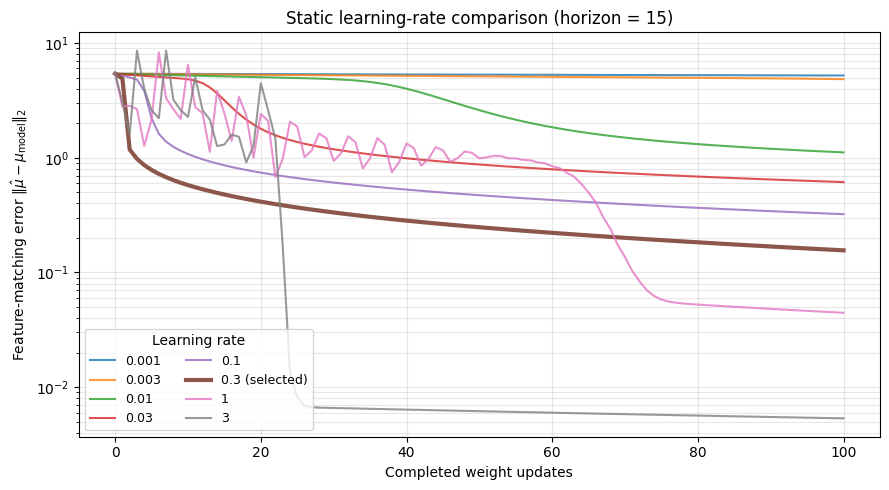

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
for run in q1_results:
    rate = run["learning_rate"]
    selected = rate == selected_learning_rate
    ax.plot(
        np.arange(n_epochs + 1),
        run["errors"],
        label=f"{rate:g}" + (" (selected)" if selected else ""),
        linewidth=3.0 if selected else 1.5,
        alpha=1.0 if selected else 0.8,
    )

ax.set_yscale("log")
ax.set_xlabel("Completed weight updates")
ax.set_ylabel(r"Feature-matching error $\|\hat\mu-\mu_{\mathrm{model}}\|_2$")
ax.set_title(f"Static learning-rate comparison (horizon = {horizon})")
ax.legend(title="Learning rate", ncol=2, fontsize=9)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

In [6]:
print("Average demonstration feature counts:", demo_feature_counts)
print(f"Initial feature-matching error: {q1_results[0]['errors'][0]:.6f}")
print(f"{'Learning rate':>13} | {'Error after 100 updates':>23} | {'Error increases':>15}")
print("-" * 59)
for run in q1_results:
    print(
        f"{run['learning_rate']:13g} | "
        f"{run['errors'][-1]:23.6f} | "
        f"{run['increases']:15d}"
    )
print(f"Selected learning rate: {selected_learning_rate:g}")

Average demonstration feature counts: [6.5 0.5 0.  1. ]
Initial feature-matching error: 5.402582
Learning rate | Error after 100 updates | Error increases
-----------------------------------------------------------
        0.001 |                5.213127 |               0
        0.003 |                4.845320 |               0
         0.01 |                1.113385 |               0
         0.03 |                0.613459 |               0
          0.1 |                0.322001 |               0
          0.3 |                0.155798 |               0
            1 |                0.044488 |              23
            3 |                0.005343 |               7
Selected learning rate: 0.3


# Q2

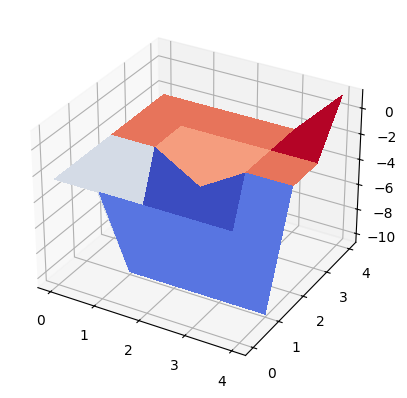

In [7]:
n_epochs = 100
horizon = 15
learning_rate = 0.3
r_weights, loss = maxEntIRL(
        trans_mat,
        state_features,
        demos,
        seed_weights,
        n_epochs,
        horizon,
        learning_rate,
        term_index,
    )

    # Construct reward function from weights and state features
reward_fxn = []
for s_i in range(25):
    reward_fxn.append(np.dot(r_weights, state_features[s_i]))
reward_fxn = np.reshape(reward_fxn, (5, 5))

# Plot reward function
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
X = np.arange(0, 5, 1)
Y = np.arange(0, 5, 1)
X, Y = np.meshgrid(X, Y)
surf = ax.plot_surface(
    X,
    Y,
    reward_fxn,
    rstride=1,
    cstride=1,
    cmap=cm.coolwarm,
    linewidth=0,
    antialiased=False,
)
plt.show()

In [8]:
print(r_weights@ state_features[12])

-4.522262647539184
